In [77]:
# Import the necessary libraries

import os
import json
import torch
import sklearn
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
from pathlib import Path
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from wordcloud import WordCloud

from sklearn.decomposition import PCA
import scipy.cluster.hierarchy as sch
from category_encoders import BinaryEncoder
from sklearn.metrics import pairwise_distances
from transformers import BertTokenizer, BertModel
from sklearn.metrics import silhouette_score, 
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_samples

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import SpectralClustering
from sklearn.cluster import AffinityPropagation

In [2]:
print(f"Pandas: {pd.__version__}")
print(f"Numpy: {np.__version__}")
print(f"Seaborn: {sns.__version__}")
print(f"Transformers: {torch.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

Pandas: 2.1.3
Numpy: 1.26.0
Seaborn: 0.12.2
Transformers: 2.1.1+cpu
Scikit-learn: 1.3.2


In [3]:
# A class to load the data from the json files

class DataLoader:
    def __init__(self, data_path):
        self.data_path = data_path

    def load_data(self):
        data_list = []

        for file in os.listdir(self.data_path):
            if file.endswith('.json'):
                data = self._extract_data(os.path.join(self.data_path, file))
                if all(value != '' for value in data.values()):
                    data_list.append(data)

        return pd.DataFrame(data_list)

    def _extract_data(self, file_path):
        with open(file_path, 'r', encoding='utf-8') as file:
            data = json.load(file)

        protocol = data.get('protocolSection', {})
        identification = protocol.get('identificationModule', {})
        description = protocol.get('descriptionModule', {})
        conditions = protocol.get('conditionsModule', {})
        design = protocol.get('designModule', {})
        eligibility = protocol.get('eligibilityModule', {})

        primary_purpose = design.get('designInfo', {}).get('primaryPurpose', '')


        extracted_data = {
            "NCT ID": self._try_except(identification, 'nctId'),
            "Study Type": self._try_except(design, 'studyType'),
            "Standard Ages": self._try_except(eligibility, 'stdAges', join=True),
            "Conditions": self._try_except(conditions, 'conditions', join=True),
            "Eligibility Criteria": self._try_except(eligibility, 'eligibilityCriteria'),
            "Sex": self._try_except(eligibility, 'sex')
        }

        return extracted_data

    def _try_except(self, data_dict, field_name, join=False):
        try:
            value = data_dict.get(field_name, '')
            if join and isinstance(value, list):
                return ", ".join(value)
            return value
        except Exception as e:
            print(f"Error extracting {field_name}: {str(e)}")
            return ''

In [4]:
def extract_raw_data(input_dir=None, output_file=None):
    '''
    Extracts raw data from the json files and saves it to a csv file.

    Parameters:
    - input_dir (str): The directory containing the input JSON files.
    - output_file (str): The name of the CSV file to save the raw data.

    Returns:
    None
    '''
    if input_dir is None or output_file is None:
        raise ValueError("Both 'input_dir' and 'output_file' must be specified.")

    # Assuming DataLoader is a class that loads data from JSON files
    dataloader = DataLoader(input_dir)
    raw_data = dataloader.load_data()

    # Save raw data to CSV
    raw_data.to_csv(output_file, index=False)

    print(f"Raw data extracted to {output_file}")


In [5]:
input_dir = Path(r'.\data\ctg-studies.json')
output_file = Path(r'.\data\ctg-studies.csv')

extract_raw_data(input_dir=input_dir, output_file=output_file)

Raw data extracted to data\ctg-studies.csv


In [6]:
raw_data = pd.read_csv(r'.\data\ctg-studies.csv')
raw_data.isna().sum()

NCT ID                  0
Study Type              0
Standard Ages           0
Conditions              0
Eligibility Criteria    0
Sex                     0
dtype: int64

In [7]:
raw_data.describe()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
count,1266,1266,1266,1266,1266,1266
unique,1266,3,6,862,1254,3
top,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Multiple Myeloma,"Inclusion Criteria:\n\n1. Age ≥18 years old, m...",ALL
freq,1,1198,836,78,3,1239


In [1]:
raw_data.head()

NameError: name 'raw_data' is not defined

In [9]:
raw_data['Study Type'].value_counts()

Study Type
INTERVENTIONAL     1198
OBSERVATIONAL        63
EXPANDED_ACCESS       5
Name: count, dtype: int64

In [10]:
raw_data['Standard Ages'].value_counts()

Standard Ages
ADULT, OLDER_ADULT           836
CHILD, ADULT, OLDER_ADULT    316
CHILD, ADULT                  97
ADULT                          9
CHILD                          7
OLDER_ADULT                    1
Name: count, dtype: int64

In [11]:
raw_data['Sex'].value_counts()

Sex
ALL       1239
FEMALE      15
MALE        12
Name: count, dtype: int64

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Bhanuteja\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Bhanuteja\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


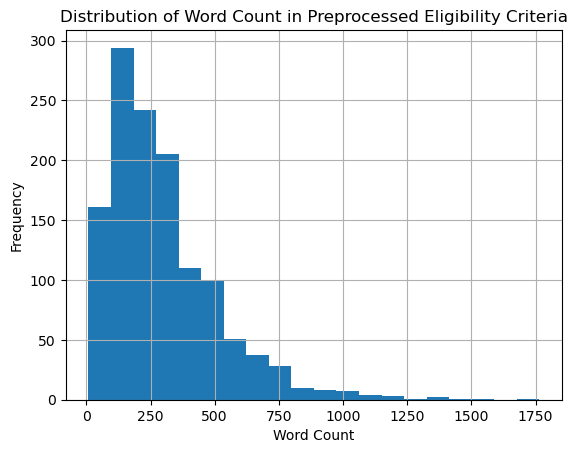

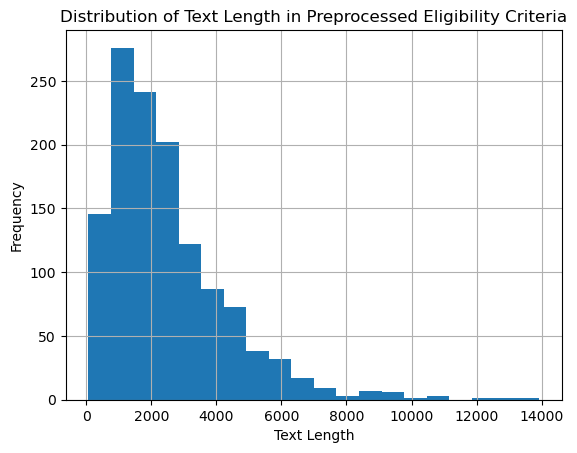

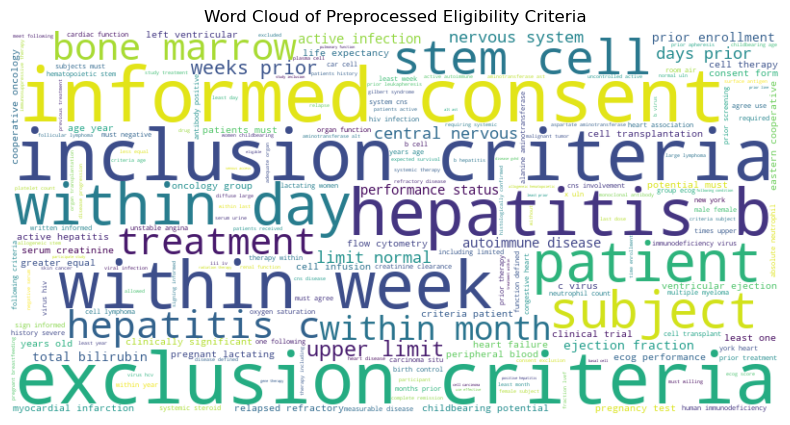

In [86]:
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import nltk
import string
nltk.download('punkt')
nltk.download('stopwords')

# Assuming 'raw_data' is your existing DataFrame with eligibility criteria text
# Make sure 'eligibility_criteria' is the column name containing the text

# Tokenization, lowercase, remove stopwords, and punctuations
stop_words = set(stopwords.words("english"))
punctuation = set(string.punctuation)

def preprocess_text(text):
    tokens = word_tokenize(text)
    tokens = [word.lower() for word in tokens if word.isalpha()]  # Remove non-alphabetic tokens
    tokens = [word for word in tokens if word not in stop_words]   # Remove stopwords
    tokens = [word for word in tokens if word not in punctuation]  # Remove punctuation
    return ' '.join(tokens)

# Preprocess eligibility criteria and add to DataFrame
raw_data['preprocessed_eligibility'] = raw_data['Eligibility Criteria'].apply(preprocess_text)

# Exploratory Data Analysis (EDA)
# You can perform various analyses depending on your goals. Here's a simple example:

# Word count distribution
raw_data['word_count'] = raw_data['preprocessed_eligibility'].apply(lambda x: len(x.split()))
raw_data['word_count'].hist(bins=20)
plt.title('Distribution of Word Count in Preprocessed Eligibility Criteria')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.show()

raw_data['text_length'] = raw_data['preprocessed_eligibility'].apply(len)
raw_data['text_length'].hist(bins=20)
plt.title('Distribution of Text Length in Preprocessed Eligibility Criteria')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.show()

# Top frequent words
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = ' '.join(raw_data['preprocessed_eligibility'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Preprocessed Eligibility Criteria')
plt.show()


In [88]:
# Assuming 'raw_data' is your DataFrame with preprocessed eligibility criteria
count_long_texts = len(raw_data[raw_data['preprocessed_eligibility'].apply(len) > 5000])

print(f"Number of trials with preprocessed text length greater than 8000: {count_long_texts}")

Number of trials with preprocessed text length greater than 8000: 116


In [90]:
raw_data = raw_data[raw_data['preprocessed_eligibility'].apply(len) <= 5000]

In [91]:
bert_model = BertModel.from_pretrained("bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16")
tokenizer = BertTokenizer.from_pretrained("bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16")

In [ ]:
def calculate_optimal_chunk_size(max_token_limit, average_text_length, safety_margin=10):
    # Calculate an estimated chunk size with a safety margin
    optimal_chunk_size = (max_token_limit - safety_margin) // 2  # Assuming even distribution of tokens

    # Adjust the chunk size based on the average text length
    if optimal_chunk_size > average_text_length:
        optimal_chunk_size = min(optimal_chunk_size, average_text_length)

    return optimal_chunk_size

# Example usage
max_token_limit = 512  # Adjust based on your BERT model
average_text_length = 300  # Calculate based on your preprocessed text

optimal_chunk_size = calculate_optimal_chunk_size(max_token_limit, average_text_length)
print(f"Optimal Chunk Size: {optimal_chunk_size}")


In [12]:
def extract_features(data=None, bert_model=None, tokenizer=None, encoder=BinaryEncoder,col='NCT ID'):
    '''
    Extracts features from the eligibility criteria using the BERT model.

    Parameters:
    - data (pd.DataFrame): The data containing the eligibility criteria.
    - bert_model (str): The name of the BERT model to use.
    - tokenizer (str): The name of the tokenizer to use.

    Returns:
    pd.DataFrame: The data with the extracted features.
    '''
    if data is None or bert_model is None or tokenizer is None:
        raise ValueError("All parameters must be specified.")

    # Load the BERT model and tokenizer
    bert_model = BertModel.from_pretrained(bert_model)
    tokenizer = BertTokenizer.from_pretrained(tokenizer)

    # Extract features from the eligibility criteria
    features = []
    for text in tqdm(data[col]):
        inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        outputs = bert_model(**inputs)
        features.append(outputs.pooler_output.detach().numpy())

    features = [feature.flatten() for feature in features]
    # Add the extracted features to the data
    features = pd.DataFrame(features)
    if col == 'NCT ID':
        features.columns = [f"feature_{i}" for i in range(features.shape[1])]
    else:
        features.columns = [f"feature_{i+1024}" for i in range(features.shape[1])] 

    return features

# Datasets

In [13]:
feature_matrix_biobert = pd.read_csv(r'.\data\feature_matrix\feature_matrix_biobert.csv')
feature_matrix_bluebert = pd.read_csv(r'.\data\feature_matrix\feature_matrix_bluebert.csv')
feature_matrix_biomedbert = pd.read_csv(r'.\data\feature_matrix\feature_matrix_biomedbert.csv')

In [14]:
# Function to plot silhouette plots
# Inspired from scikit learn
# https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html

def plot_silhouette_samples(X, labels):
    silhouette_avg = silhouette_score(X, labels)
    print("The average silhouette_score is :", silhouette_avg)

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, labels)

    plt.figure(figsize=(8, 6))
    y_lower = 10

    for i in np.unique(labels):
        ith_cluster_silhouette_values = sample_silhouette_values[labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / len(np.unique(labels)))
        plt.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Label the silhouette plots with their cluster numbers at the middle
        plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for the next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    plt.title("Silhouette plot for the various clusters")
    plt.xlabel("The silhouette coefficient values")
    plt.ylabel("Cluster label")

    # The vertical line for the average silhouette score of all the values
    plt.axvline(x=silhouette_avg, color="red", linestyle="--")

    plt.yticks([])  # Clear the y-axis labels / ticks
    plt.xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    plt.show()

# KMeans

## Bluebert

In [15]:
# Dataset Bluebert
X_bluebert = feature_matrix_bluebert.drop(columns=['NCT ID'])

# PCA
pca_bluebert = PCA(n_components=256)
X_pca_bluebert = pca_bluebert.fit_transform(X_bluebert)
print(f"Explained variance ratio - Bluebert: {sum(pca_bluebert.explained_variance_ratio_)}")

Explained variance ratio - Bluebert: 0.9989227153155639


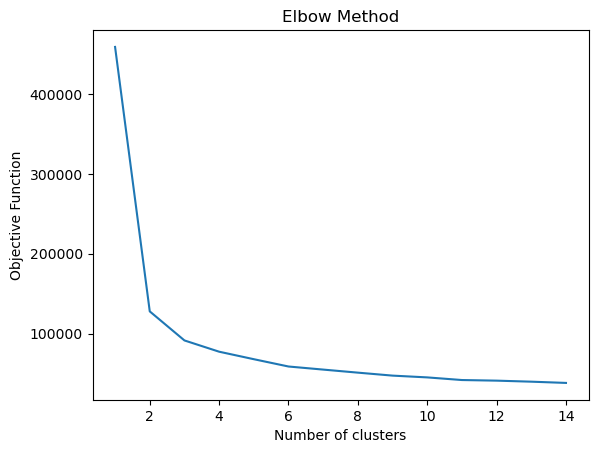

In [16]:
# Finding optimal number of clusters using elbow method

objective_function = []

for i in range(1, 15):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=1)
    kmeans.fit(X_pca_bluebert)
    objective_function.append(kmeans.inertia_)

plt.plot(range(1, 15), objective_function)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Objective Function')
plt.show()

In the plot we can clearly see the elbow is at 2
So the optimal number of clusters is 2

The average silhouette_score is : 0.6625642451182385


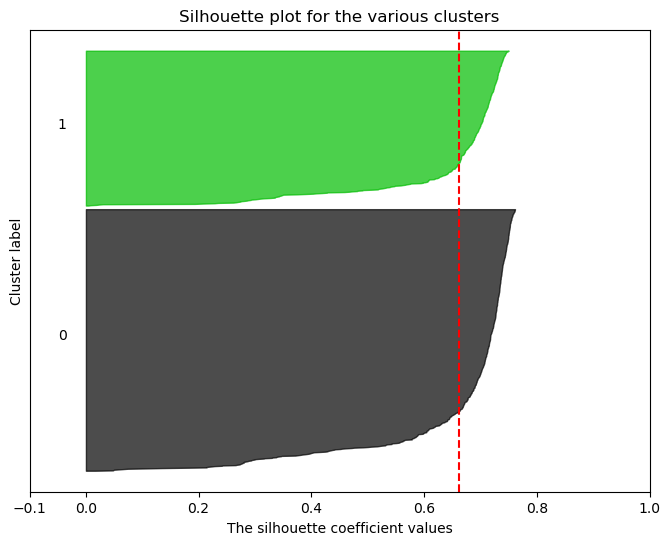

In [17]:
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=1)
kmeans.fit(X_pca_bluebert)
labels = kmeans.labels_

plot_silhouette_samples(X_pca_bluebert, labels)

## Biomedbert

In [18]:
# Dataset Biomedbert
X_biomedbert = feature_matrix_biomedbert.drop(columns=['NCT ID'])

# PCA
pca_biomedbert = PCA(n_components=1024)
X_pca_biomedbert = pca_biomedbert.fit_transform(X_biomedbert)
print(f"Explained variance ratio - Biomedbert: {sum(pca_biomedbert.explained_variance_ratio_)}")

Explained variance ratio - Biomedbert: 0.9998763227130608


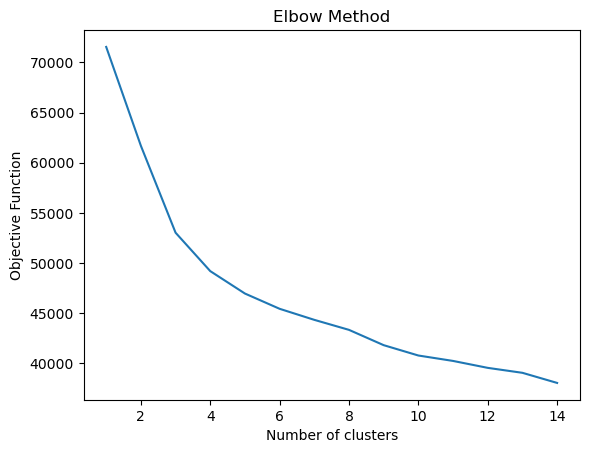

In [19]:
# Finding optimal number of clusters using elbow method

objective_function = []

for i in range(1, 15):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=1)
    kmeans.fit(X_pca_biomedbert)
    objective_function.append(kmeans.inertia_)

plt.plot(range(1, 15), objective_function)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Objective Function')
plt.show()

In the plot we can clearly see the elbow is at 3
So the optimal number of clusters is 3

The average silhouette_score is : 0.1790932843063201


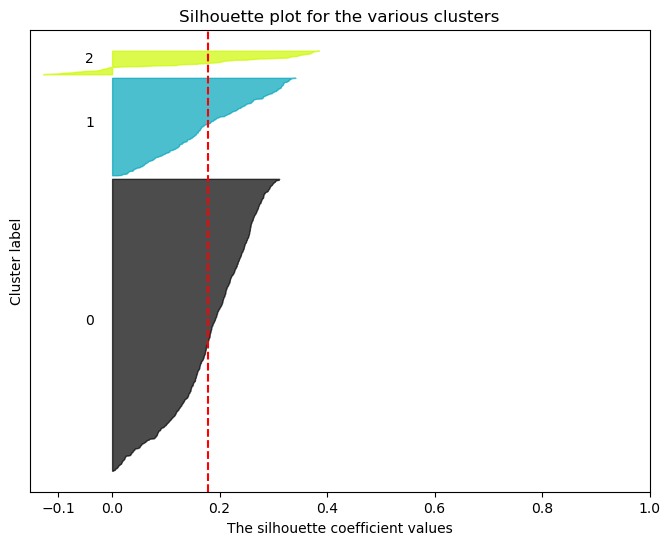

In [20]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=1)
kmeans.fit(X_pca_biomedbert)
labels = kmeans.labels_

plot_silhouette_samples(X_pca_biomedbert, labels)

## Biobert

In [21]:
# Dataset biobert
X_biobert = feature_matrix_biobert.drop(columns=['NCT ID'])

# PCA
pca_biobert = PCA(n_components=256)
X_pca_biobert = pca_biobert.fit_transform(X_biobert)
print(f"Explained variance ratio - Biobert: {sum(pca_biobert.explained_variance_ratio_)}")

Explained variance ratio - Biobert: 0.9972725938818202


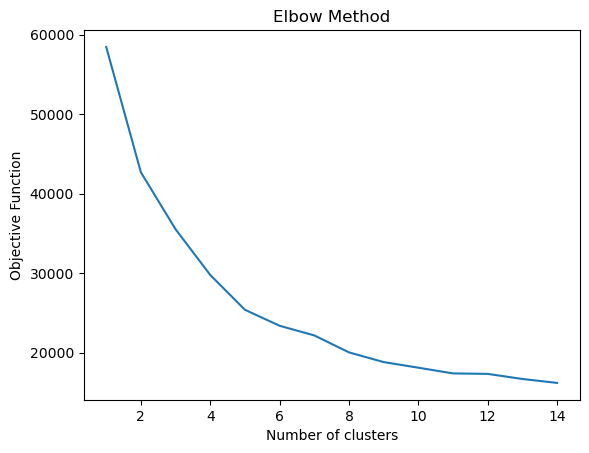

In [22]:
# Finding optimal number of clusters using elbow method

objective_function = []

for i in range(1, 15):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=1)
    kmeans.fit(X_pca_biobert)
    objective_function.append(kmeans.inertia_)

plt.plot(range(1, 15), objective_function)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Objective Function')
plt.show()

In the plot we can clearly see the elbow is at 3
So the optimal number of clusters is 3

The average silhouette_score is : 0.1790932843063201


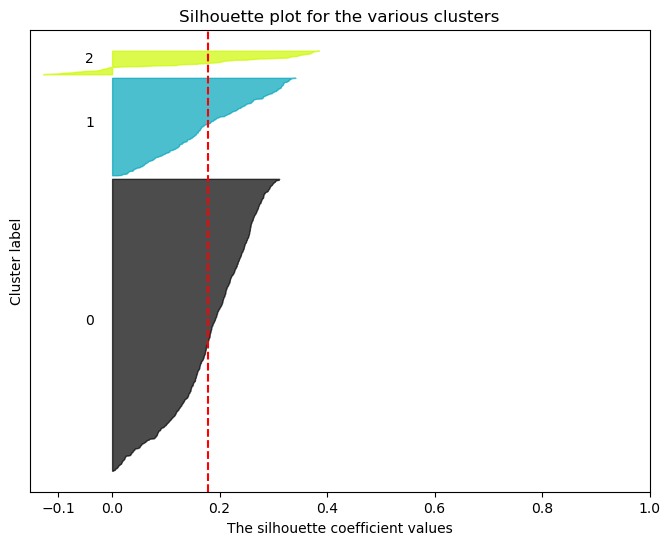

In [23]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=1)
kmeans.fit(X_pca_biomedbert)
labels = kmeans.labels_

plot_silhouette_samples(X_pca_biomedbert, labels)

# Agglomerative Clustering

## Bluebert

Optimal number of clusters: 2


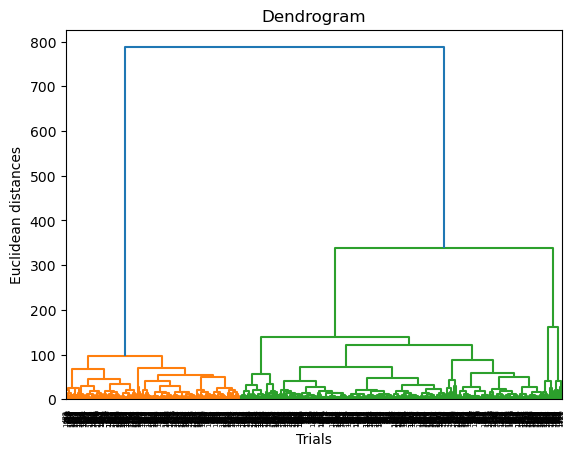

In [24]:
# Dendogram
import scipy.cluster.hierarchy as sch
cluster_visualising=sch.dendrogram(sch.linkage(X_pca_bluebert,method='ward', metric='euclidean'))

unique_colors = np.unique(cluster_visualising['color_list'])
print(f"Optimal number of clusters: {len(unique_colors)-1}")
plt.title('Dendrogram')
plt.xlabel('Trials')
plt.ylabel('Euclidean distances')
plt.show()

The average silhouette_score is : 0.6456583391934517


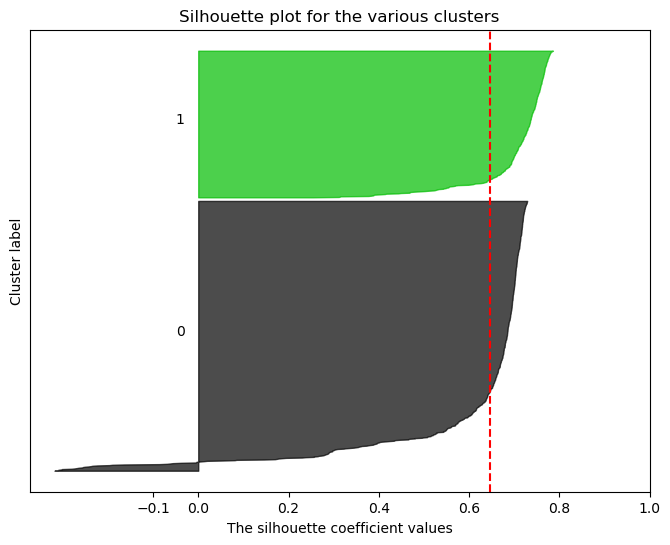

[0 1 0 ... 1 0 1]


In [25]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
labels = agglomerative_clustering.fit_predict(X_pca_bluebert)

plot_silhouette_samples(X_pca_bluebert, labels)
print(labels)

## Biobert

Optimal number of clusters: 7


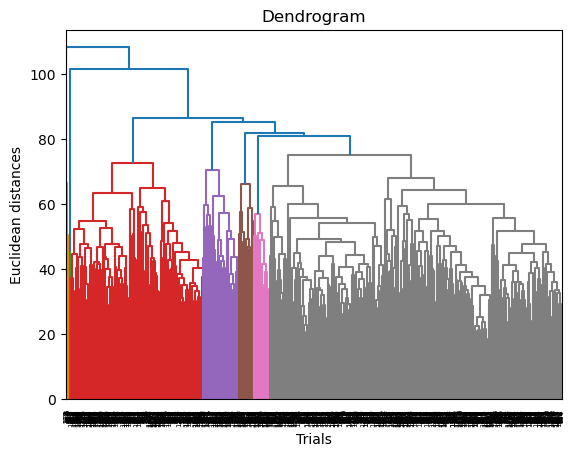

In [26]:
# Dendogram

cluster_visualising=sch.dendrogram(sch.linkage(X_pca_biobert,method='complete', metric='cityblock'))

unique_colors = np.unique(cluster_visualising['color_list'])
print(f"Optimal number of clusters: {len(unique_colors)-1}")
plt.title('Dendrogram')
plt.xlabel('Trials')
plt.ylabel('Euclidean distances')
plt.show()

The average silhouette_score is : 0.25719069817381796


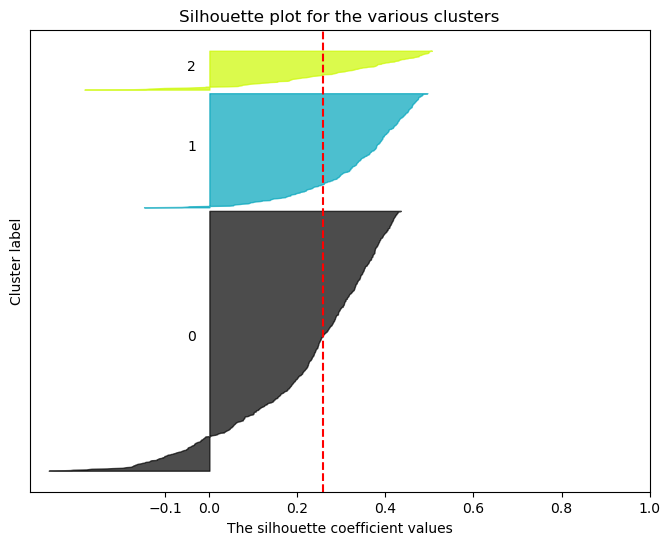

In [27]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels = agglomerative_clustering.fit_predict(X_pca_biobert)

plot_silhouette_samples(X_pca_biobert, labels)

## Biomedbert

Optimal number of clusters: 3


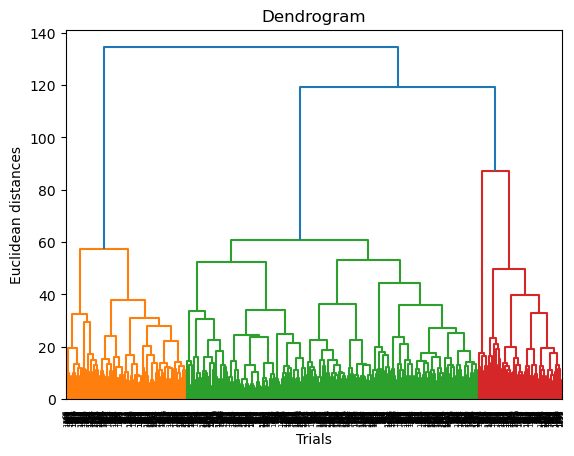

In [28]:
# Dendogram
import scipy.cluster.hierarchy as sch
cluster_visualising=sch.dendrogram(sch.linkage(X_pca_biomedbert,method='ward'))
unique_colors = np.unique(cluster_visualising['color_list'])
print(f"Optimal number of clusters: {len(unique_colors)-1}")

plt.title('Dendrogram')
plt.xlabel('Trials')
plt.ylabel('Euclidean distances')
plt.show()

The average silhouette_score is : 0.1363516627472447


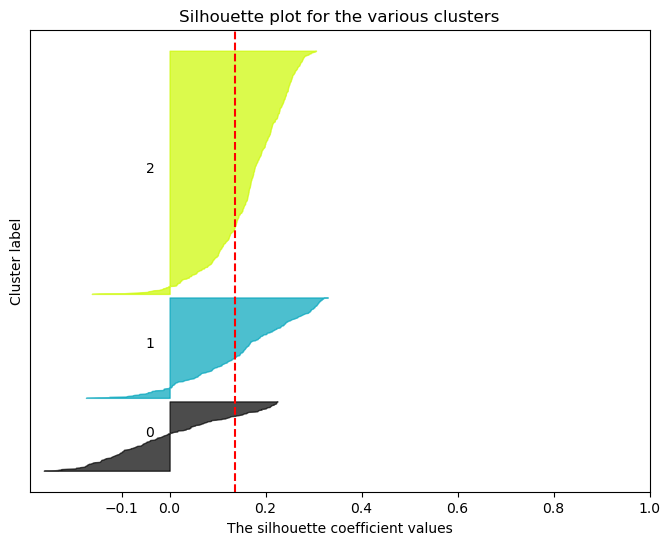

In [29]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels = agglomerative_clustering.fit_predict(X_pca_biomedbert)

plot_silhouette_samples(X_pca_biomedbert, labels)

In [30]:
def plot_dendograms(dataset=None):
    linkages = ['single', 'complete', 'average']
    metrics = ['euclidean', 'cityblock', 'cosine']

    for linkage in linkages:
        print(f"Linkage: {linkage}")
        for metric in metrics:
            print(f"Metric: {metric}")
            cluster_visualising=sch.dendrogram(sch.linkage(X_pca_biobert,method=linkage, metric=metric))
            unique_colors = np.unique(cluster_visualising['color_list'])
            print(f"Optimal number of clusters: {len(unique_colors)-1}")
            plt.title('Dendrogram')
            plt.xlabel('Trials')
            plt.ylabel('Euclidean distances')
            plt.show()
        print()

Linkage: single
Metric: euclidean
Optimal number of clusters: 3


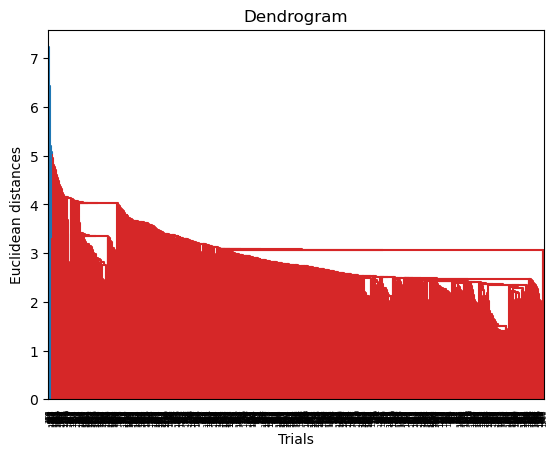

Metric: cityblock
Optimal number of clusters: 5


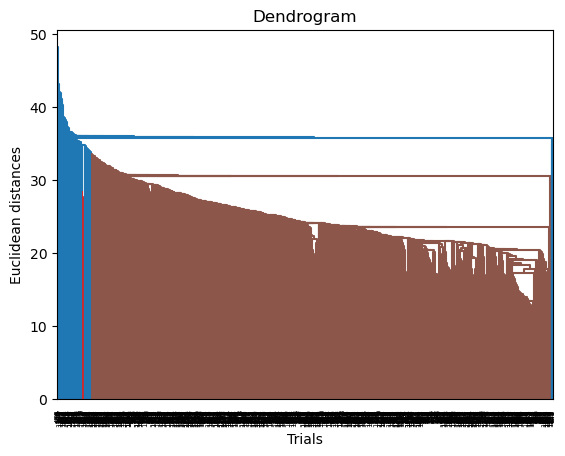

Metric: cosine
Optimal number of clusters: 4


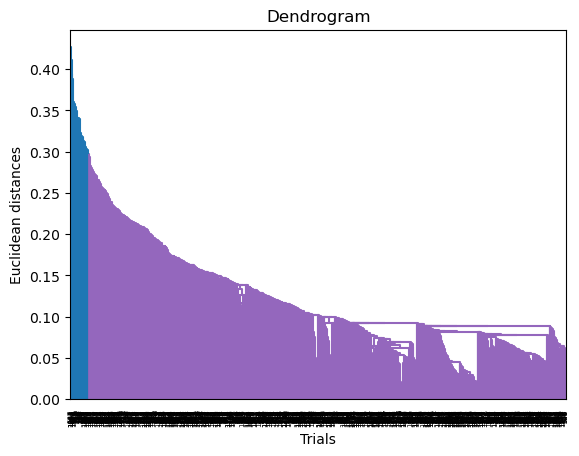


Linkage: complete
Metric: euclidean
Optimal number of clusters: 5


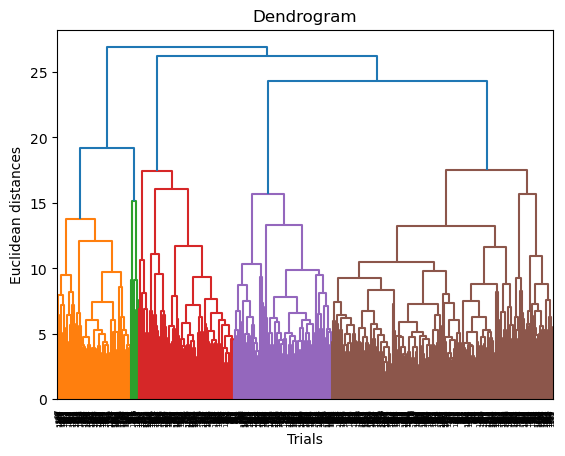

Metric: cityblock
Optimal number of clusters: 7


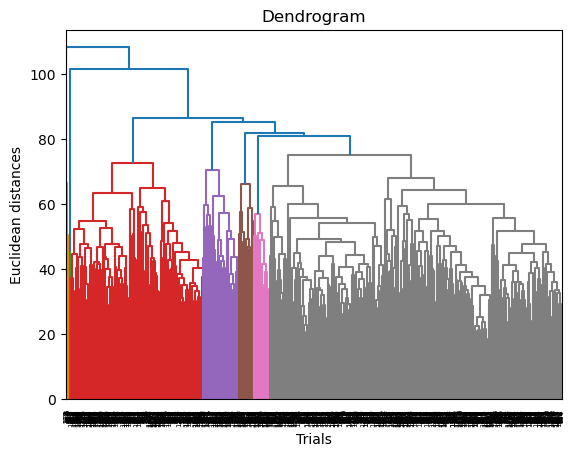

Metric: cosine
Optimal number of clusters: 9


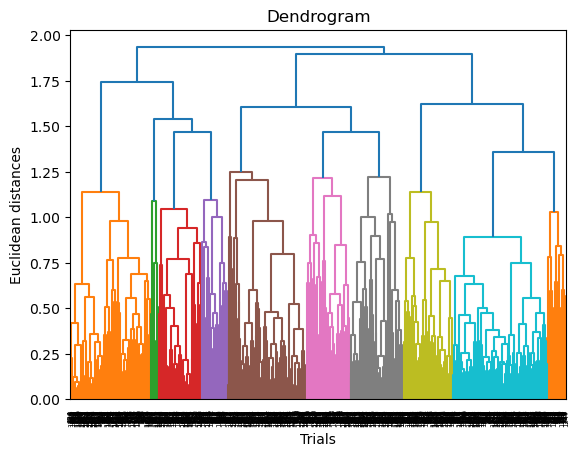


Linkage: average
Metric: euclidean
Optimal number of clusters: 6


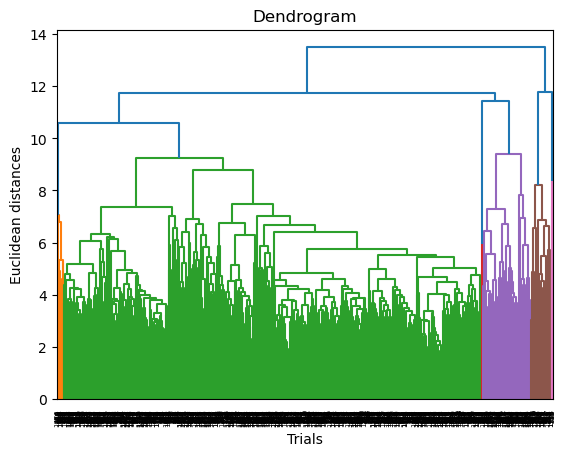

Metric: cityblock
Optimal number of clusters: 1


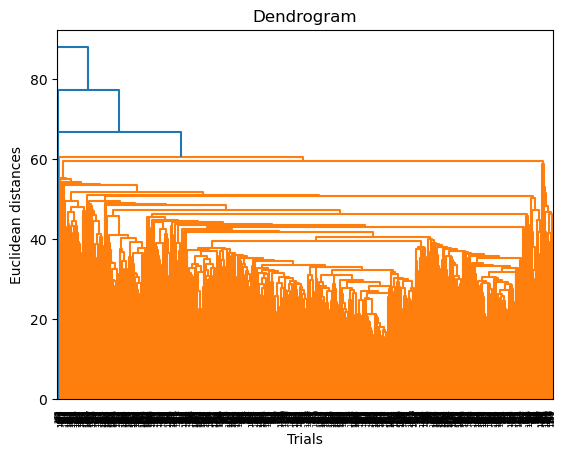

Metric: cosine
Optimal number of clusters: 5


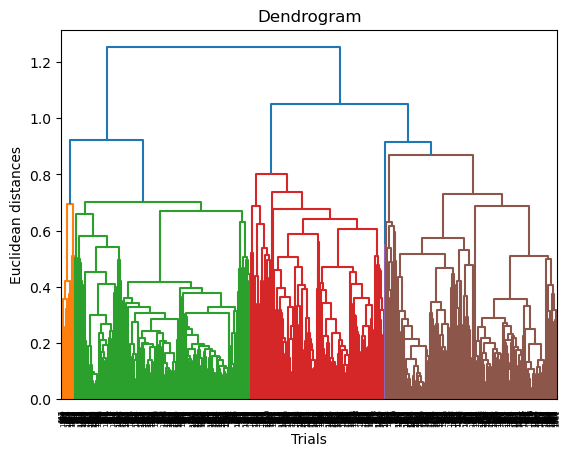

In [31]:
plot_dendograms(X_pca_biobert)

Linkage: single
Metric: euclidean
Optimal number of clusters: 3


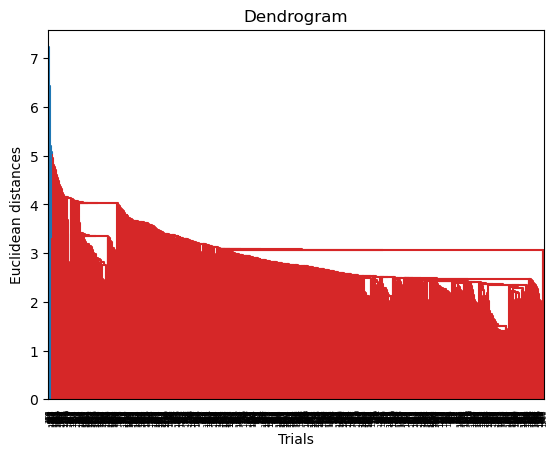

Metric: cityblock
Optimal number of clusters: 5


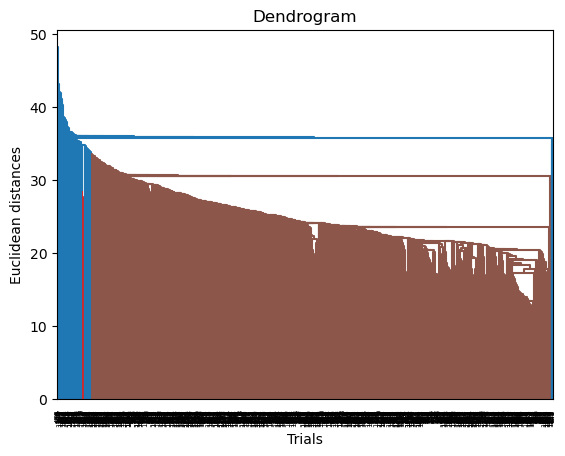

Metric: cosine
Optimal number of clusters: 4


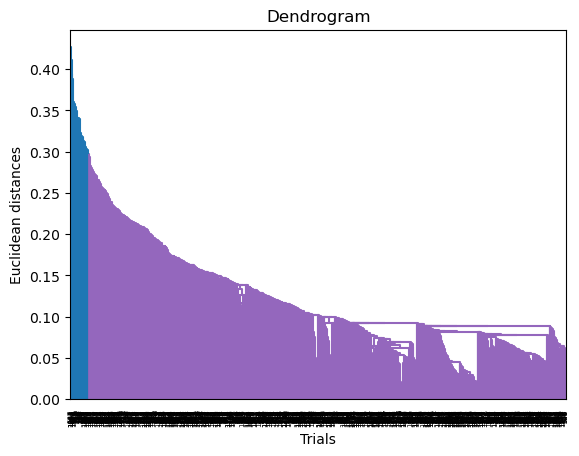


Linkage: complete
Metric: euclidean
Optimal number of clusters: 5


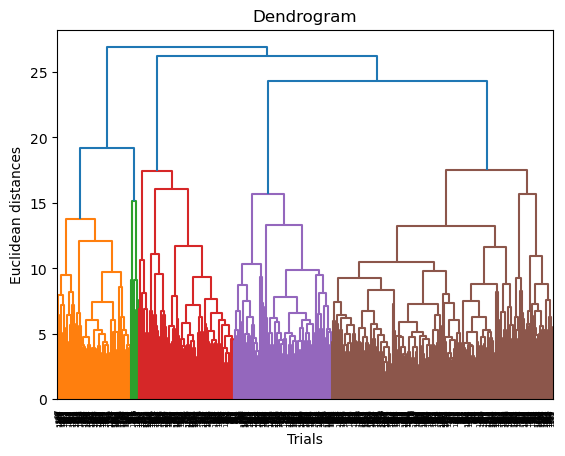

Metric: cityblock
Optimal number of clusters: 7


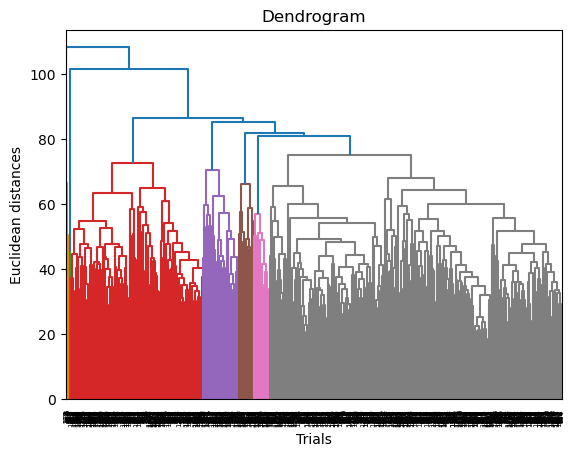

Metric: cosine
Optimal number of clusters: 9


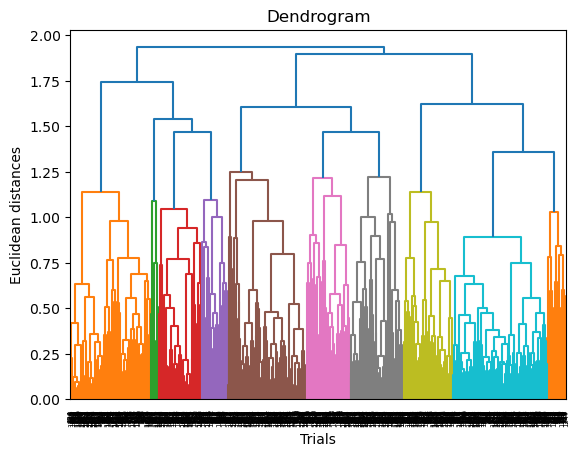


Linkage: average
Metric: euclidean
Optimal number of clusters: 6


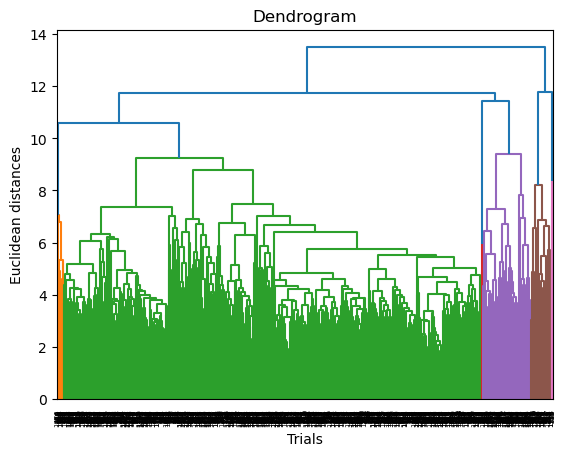

Metric: cityblock
Optimal number of clusters: 1


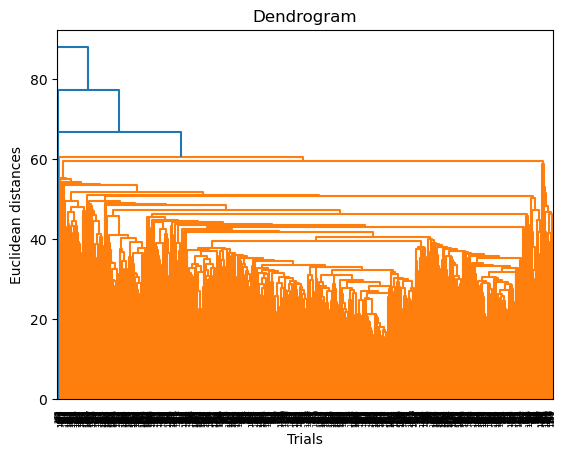

Metric: cosine
Optimal number of clusters: 5


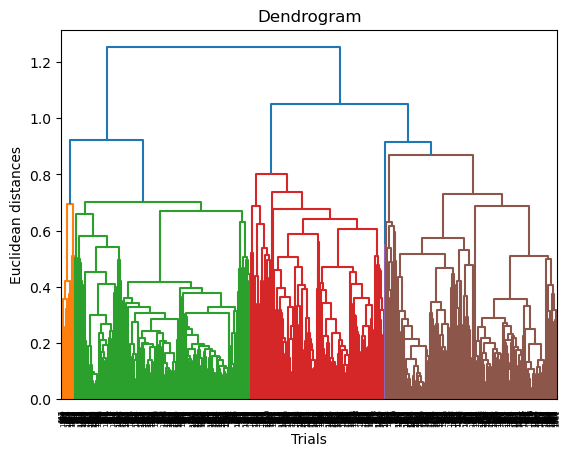

In [32]:
plot_dendograms(X_pca_bluebert)

Linkage: single
Metric: euclidean
Optimal number of clusters: 3


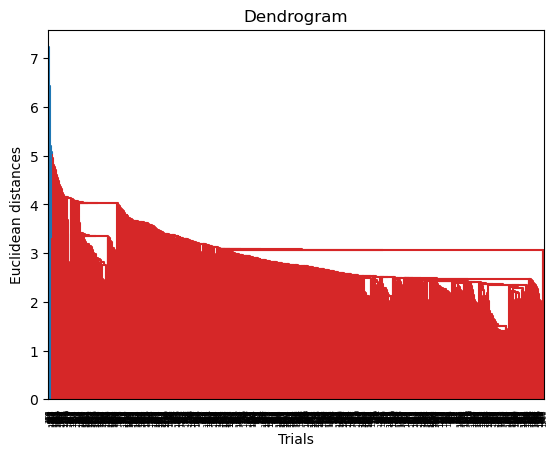

Metric: cityblock
Optimal number of clusters: 5


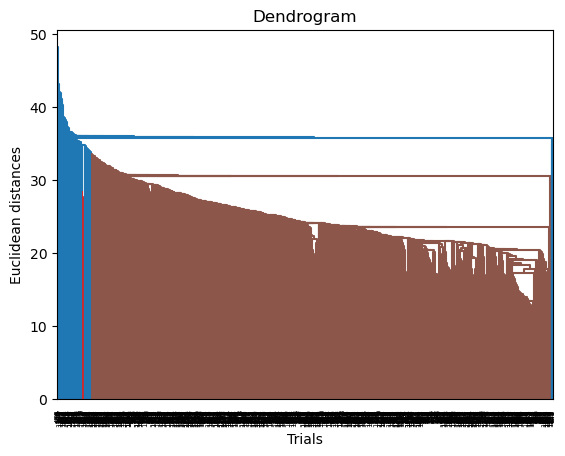

Metric: cosine
Optimal number of clusters: 4


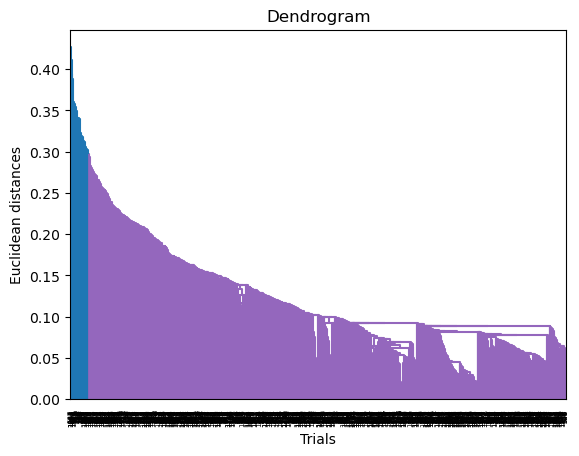


Linkage: complete
Metric: euclidean
Optimal number of clusters: 5


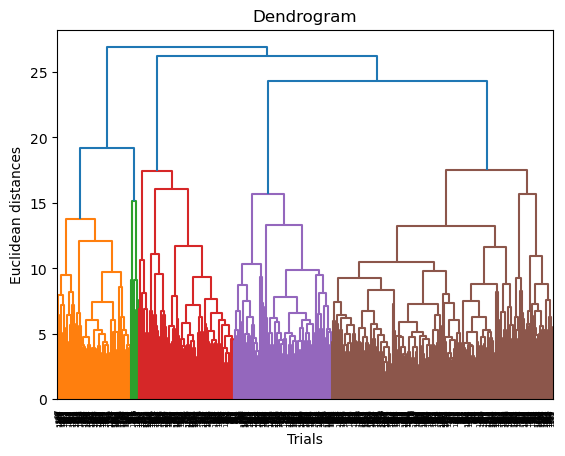

Metric: cityblock
Optimal number of clusters: 7


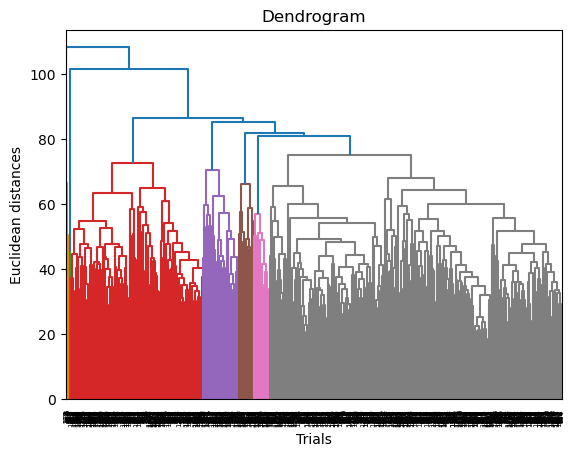

Metric: cosine
Optimal number of clusters: 9


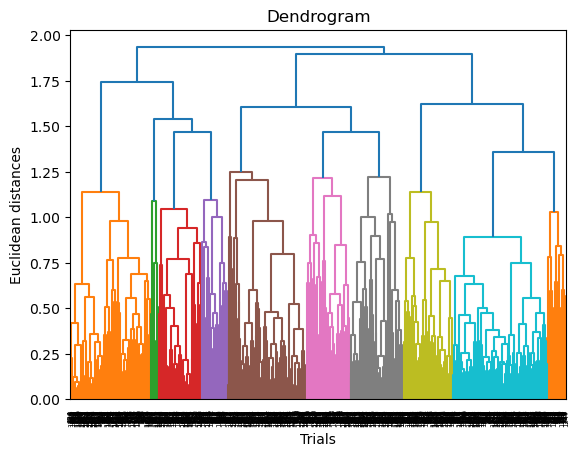


Linkage: average
Metric: euclidean
Optimal number of clusters: 6


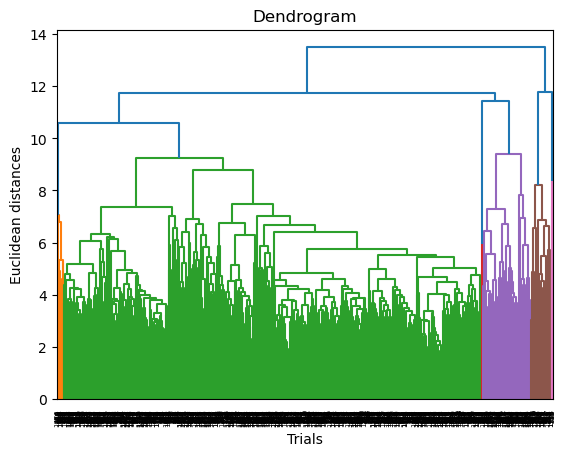

Metric: cityblock
Optimal number of clusters: 1


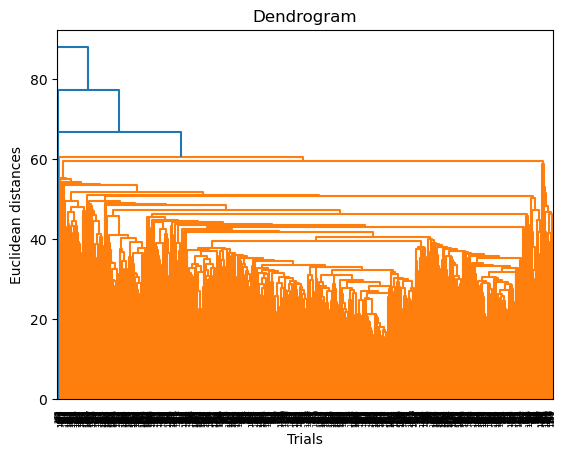

Metric: cosine
Optimal number of clusters: 5


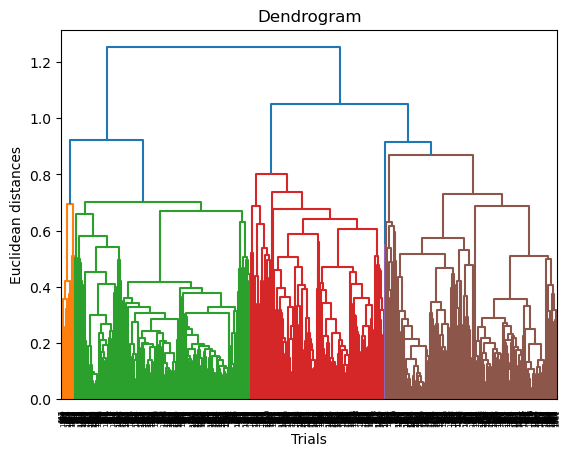

In [33]:
plot_dendograms(X_pca_bluebert)

# DBSCAN

      index  distance
1261   1261  0.000000
358     358  0.000000
975     975  0.287413
829     829  0.307799
181     181  0.357499


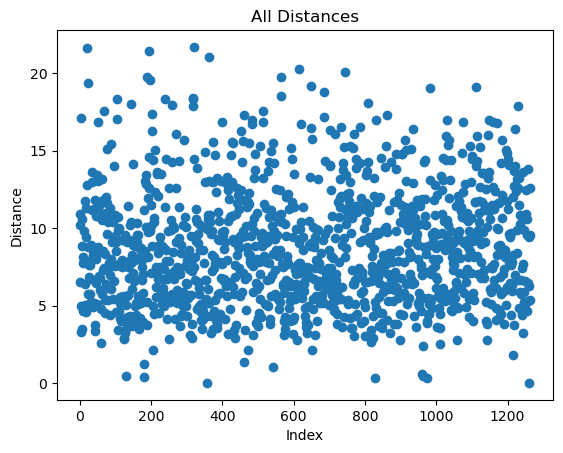

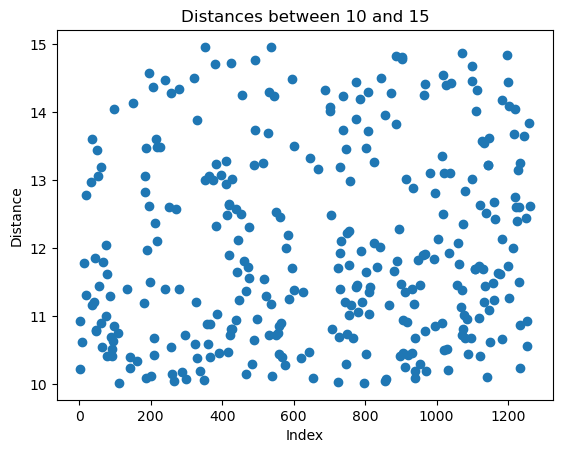

In [75]:
feature_matrix_biobert = feature_matrix_biobert.sort_values(by=['NCT ID'])

# Calculate distances between consecutive rows
dists = []
for i in range(len(feature_matrix_biobert) - 1):
    dist = np.linalg.norm(feature_matrix_biobert.iloc[i, 1:] - feature_matrix_biobert.iloc[i + 1, 1:])
    dists.append(dist)

df = pd.DataFrame({'index': range(len(dists)), 'distance': dists})
df = df.sort_values(by=['distance'], ascending=True)
print(df.head())

# Plotting distances
plt.scatter(df['index'], df['distance'])
plt.title('All Distances')
plt.xlabel('Index')
plt.ylabel('Distance')
plt.show()

# Filtering distances less than 0.5
df2 = df[(df["distance"] < 15) & (df["distance"] > 10)]
df2 = df2.sort_values(by=['distance'])

# Plotting filtered distances
plt.scatter(df2['index'], df2['distance'])
plt.title('Distances between 10 and 15')
plt.xlabel('Index')
plt.ylabel('Distance')
plt.show()

In [71]:
from sklearn.cluster import DBSCAN

X_bluebert = feature_matrix_bluebert.drop(columns=['NCT ID'])

# PCA
pca_bluebert = PCA(n_components=256)
X_pca_bluebert = pca_bluebert.fit_transform(X_bluebert)

range_eps= np.arange(10,15)
min_samples = np.arange(100,260)
max_silhouette_avg = 0
best_eps = 0
best_min_samples = 0
for i in range_eps:
    for j in min_samples:
        db=DBSCAN(eps=i,min_samples=j, metric='euclidean').fit(X_pca_bluebert)
        core_samples_mask=np.zeros_like(db.labels_,dtype=bool)
        core_samples_mask[db.core_sample_indices_]=True
        labels=db.labels_
        silhouette_avg=silhouette_score(X_pca_bluebert,labels)

        if silhouette_avg > max_silhouette_avg:
            max_silhouette_avg = silhouette_avg
            best_eps = i
            best_min_samples = j
print(f"Best eps: {best_eps}")
print(f"Best min_samples: {best_min_samples}")
print(f"Best silhouette score: {max_silhouette_avg}")

Best eps: 13
Best min_samples: 186
Best silhouette score: 0.6782308212065821


The average silhouette_score is : 0.6782308212065821


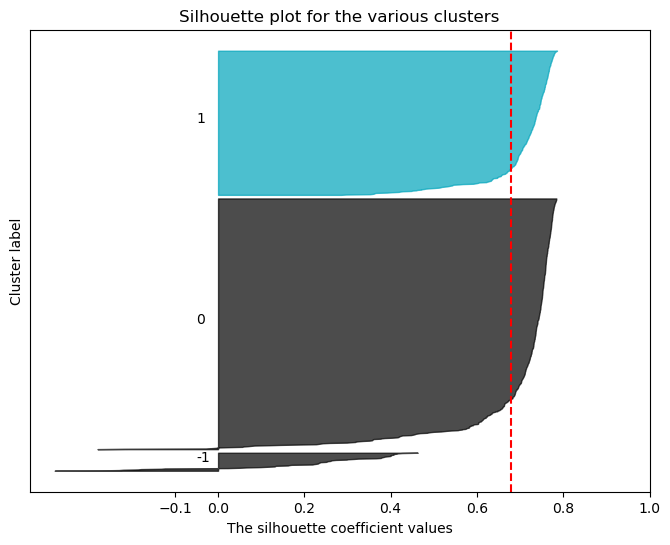

In [76]:
db=DBSCAN(eps=13,min_samples=186, metric='euclidean').fit(X_pca_bluebert)
core_samples_mask=np.zeros_like(db.labels_,dtype=bool)
core_samples_mask[db.core_sample_indices_]=True
labels=db.labels_
silhouette_avg=silhouette_score(X_pca_bluebert,labels)
plot_silhouette_samples(X_pca_bluebert, labels)